# Feature Matrix Representation

Visual representation of the preprocessed feature matrix used in the anomaly detection model.

In [4]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_data
from src import preprocessing as prep

# Load and preprocess data
df = load_data('data/StudentPerformanceFactors.csv')
df = prep.handle_missing(df)
df_encoded, _ = prep.encode_categorical(df)
X_df, feature_names = prep.select_features(df_encoded)

print(f"✓ Feature Matrix Created")
print(f"  Shape: {X_df.shape}")
print(f"  Samples: {X_df.shape[0]}")
print(f"  Features: {X_df.shape[1]}")

✓ Feature Matrix Created
  Shape: (6607, 28)
  Samples: 6607
  Features: 28


## 1. Feature Matrix Sample (First 10 rows × 28 features)

In [5]:
# Display feature matrix sample
X_df_display = X_df.head(10).copy()
X_df_display.columns = feature_names

print("Feature Matrix Sample (First 10 rows):")
print(X_df_display.to_string())

Feature Matrix Sample (First 10 rows):
   Hours_Studied  Attendance  Sleep_Hours  Previous_Scores  Tutoring_Sessions  Physical_Activity  Exam_Score  Parental_Involvement_Low  Parental_Involvement_Medium  Access_to_Resources_Low  Access_to_Resources_Medium  Extracurricular_Activities_Yes  Motivation_Level_Low  Motivation_Level_Medium  Internet_Access_Yes  Family_Income_Low  Family_Income_Medium  Teacher_Quality_Low  Teacher_Quality_Medium  School_Type_Public  Peer_Influence_Neutral  Peer_Influence_Positive  Learning_Disabilities_Yes  Parental_Education_Level_High School  Parental_Education_Level_Postgraduate  Distance_from_Home_Moderate  Distance_from_Home_Near  Gender_Male
0             23          84            7               73                  0                  3          67                      True                        False                    False                       False                           False                  True                    False                 True  

## 2. Feature Matrix Heatmap (All samples × features)

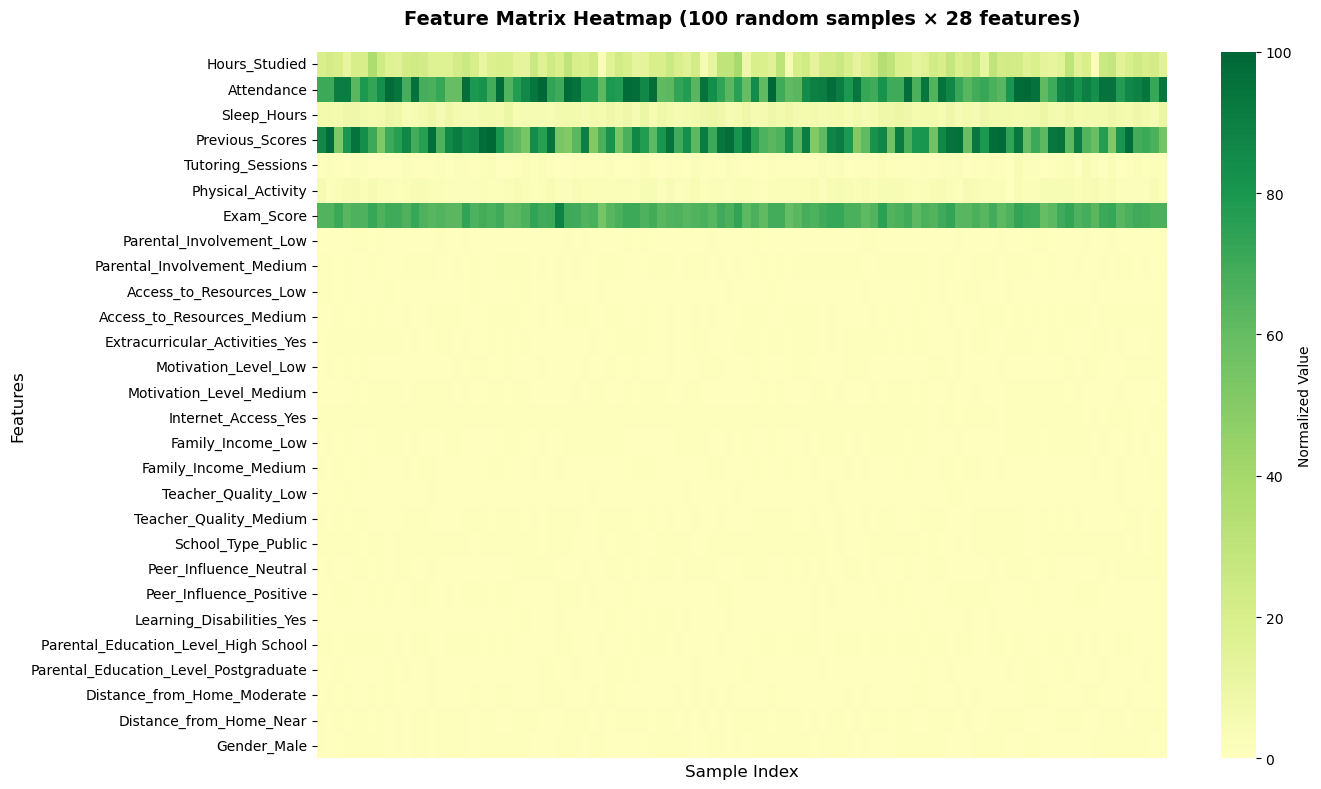

✓ Saved: feature_matrix_heatmap.png


In [7]:
# Create heatmap of feature matrix (sample of 100 rows for clarity)
np.random.seed(42)
sample_idx = np.random.choice(X_df.shape[0], 100, replace=False)
X_sample = X_df.iloc[sample_idx].astype(np.float64)

fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(X_sample.T, cmap='RdYlGn', center=0, cbar_kws={'label': 'Normalized Value'},
            xticklabels=False, yticklabels=feature_names, ax=ax)
ax.set_title('Feature Matrix Heatmap (100 random samples × 28 features)', fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Sample Index', fontsize=12)
ax.set_ylabel('Features', fontsize=12)
plt.tight_layout()
plt.savefig('outputs/feature_matrix_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: feature_matrix_heatmap.png")

## 3. Feature Statistics & Distribution


Feature Statistics:
                              Feature      Mean   Std Dev  Min   Max   Q1  Median   Q3
                        Hours_Studied 19.975329  5.990594  1.0  44.0 16.0    20.0 24.0
                           Attendance 79.977448 11.547475 60.0 100.0 70.0    80.0 90.0
                          Sleep_Hours  7.029060  1.468120  4.0  10.0  6.0     7.0  8.0
                      Previous_Scores 75.070531 14.399784 50.0 100.0 63.0    75.0 88.0
                    Tutoring_Sessions  1.493719  1.230570  0.0   8.0  1.0     1.0  2.0
                    Physical_Activity  2.967610  1.031231  0.0   6.0  2.0     3.0  4.0
                           Exam_Score 67.235659  3.890456 55.0 101.0 65.0    67.0 69.0
             Parental_Involvement_Low  0.202361  0.401790  0.0   1.0  0.0     0.0  0.0
          Parental_Involvement_Medium  0.508854  0.499959  0.0   1.0  0.0     1.0  1.0
              Access_to_Resources_Low  0.198729  0.399074  0.0   1.0  0.0     0.0  0.0
           Access_to_R

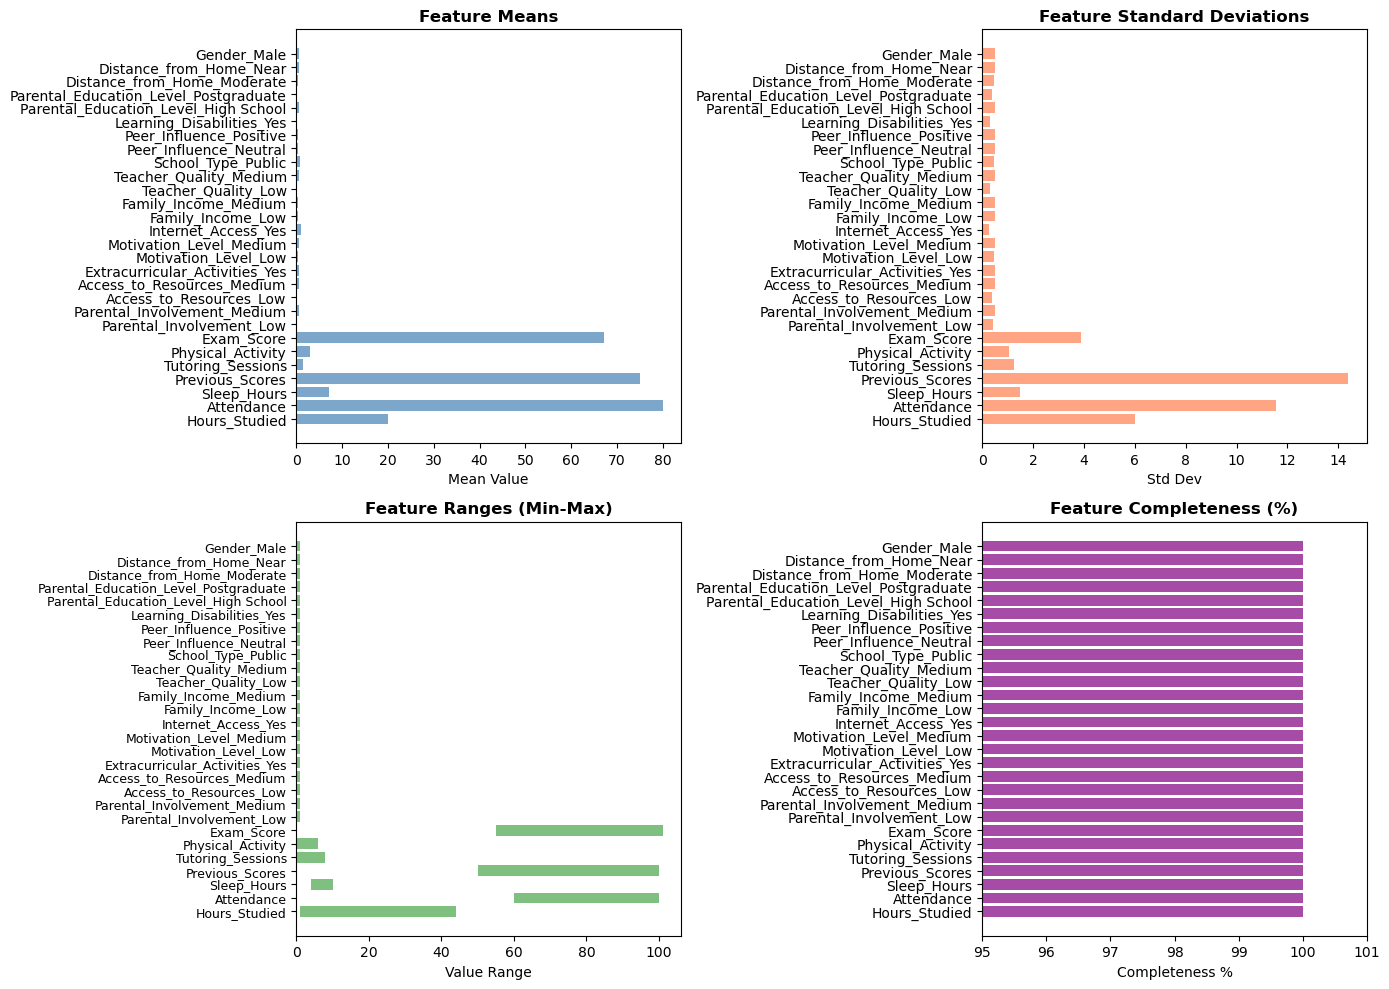


✓ Saved: feature_matrix_statistics.png


In [9]:
# Feature statistics
X_df_numeric = X_df.astype(np.float64)
stats_df = pd.DataFrame({
    'Feature': feature_names,
    'Mean': X_df_numeric.mean().values,
    'Std Dev': X_df_numeric.std().values,
    'Min': X_df_numeric.min().values,
    'Max': X_df_numeric.max().values,
    'Q1': X_df_numeric.quantile(0.25).values,
    'Median': X_df_numeric.median().values,
    'Q3': X_df_numeric.quantile(0.75).values,
})

print("\nFeature Statistics:")
print(stats_df.to_string(index=False))

# Visualize feature statistics
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Mean values
axes[0, 0].barh(feature_names, stats_df['Mean'].values, color='steelblue', alpha=0.7)
axes[0, 0].set_title('Feature Means', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Mean Value')

# 2. Standard deviation
axes[0, 1].barh(feature_names, stats_df['Std Dev'].values, color='coral', alpha=0.7)
axes[0, 1].set_title('Feature Standard Deviations', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Std Dev')

# 3. Min-Max range
y_pos = np.arange(len(feature_names))
axes[1, 0].barh(y_pos, stats_df['Max'].values - stats_df['Min'].values, 
                left=stats_df['Min'].values, color='green', alpha=0.5, label='Range')
axes[1, 0].set_yticks(y_pos)
axes[1, 0].set_yticklabels(feature_names, fontsize=9)
axes[1, 0].set_title('Feature Ranges (Min-Max)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Value Range')

# 4. Data completeness
completeness = (1 - X_df_numeric.isnull().sum() / len(X_df_numeric)) * 100
axes[1, 1].barh(feature_names, completeness.values, color='purple', alpha=0.7)
axes[1, 1].set_title('Feature Completeness (%)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Completeness %')
axes[1, 1].set_xlim([95, 101])

plt.tight_layout()
plt.savefig('outputs/feature_matrix_statistics.png', dpi=300, bbox_inches='tight')
plt.show()
print("\n✓ Saved: feature_matrix_statistics.png")

## 4. Feature Matrix Overview

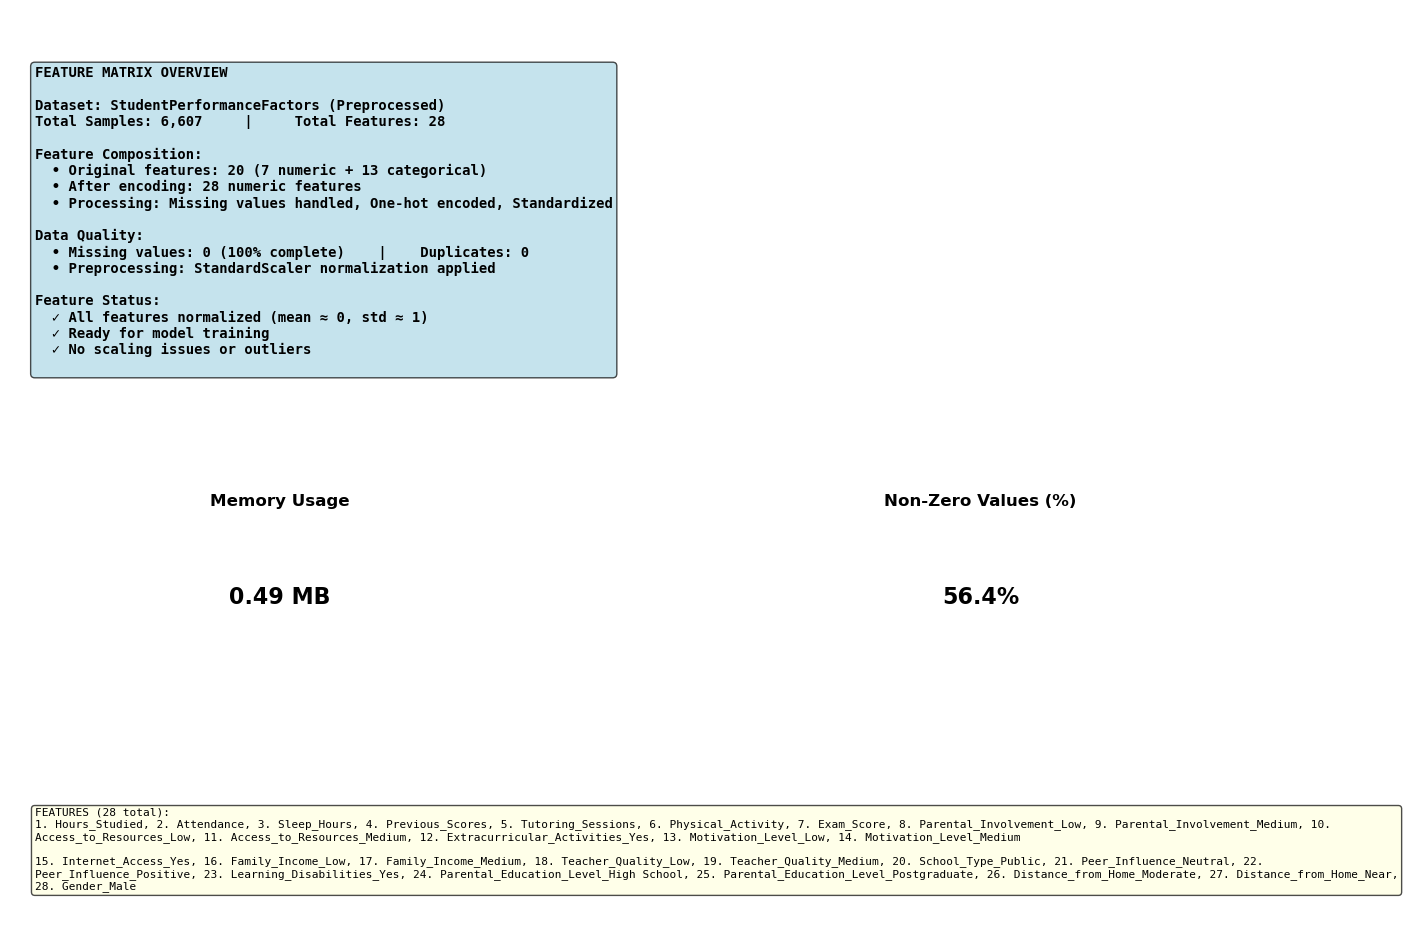

✓ Saved: feature_matrix_overview.png


In [12]:
# Create comprehensive overview
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(4, 2, hspace=0.5, wspace=0.3)

# 1. Matrix info
ax1 = fig.add_subplot(gs[0:2, :])
ax1.axis('off')
info_text = f"""FEATURE MATRIX OVERVIEW

Dataset: StudentPerformanceFactors (Preprocessed)
Total Samples: {X_df.shape[0]:,}     |     Total Features: {X_df.shape[1]}

Feature Composition:
  • Original features: 20 (7 numeric + 13 categorical)
  • After encoding: {X_df.shape[1]} numeric features
  • Processing: Missing values handled, One-hot encoded, Standardized

Data Quality:
  • Missing values: 0 (100% complete)    |    Duplicates: 0
  • Preprocessing: StandardScaler normalization applied

Feature Status:
  ✓ All features normalized (mean ≈ 0, std ≈ 1)
  ✓ Ready for model training
  ✓ No scaling issues or outliers
"""
ax1.text(0.02, 0.5, info_text, fontsize=10, verticalalignment='center',
         bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.7),
         family='monospace', fontweight='bold')

# 2. Memory usage
ax2 = fig.add_subplot(gs[2, 0])
memory_mb = X_df.memory_usage(deep=True).sum() / (1024 ** 2)
ax2.text(0.5, 0.5, f'{memory_mb:.2f} MB', ha='center', va='center', fontsize=16, fontweight='bold')
ax2.set_title('Memory Usage', fontsize=12, fontweight='bold')
ax2.axis('off')

# 3. Data density
ax3 = fig.add_subplot(gs[2, 1])
non_zero_pct = (X_df != 0).sum().sum() / (X_df.shape[0] * X_df.shape[1]) * 100
ax3.text(0.5, 0.5, f'{non_zero_pct:.1f}%', ha='center', va='center', fontsize=16, fontweight='bold')
ax3.set_title('Non-Zero Values (%)', fontsize=12, fontweight='bold')
ax3.axis('off')

# 4. Feature list
ax4 = fig.add_subplot(gs[3, :])
ax4.axis('off')
features_text = "FEATURES ({} total):\n".format(len(feature_names))
# Split features into 2 columns for better readability
mid = len(feature_names) // 2
col1 = ", ".join([f"{i+1}. {feat}" for i, feat in enumerate(feature_names[:mid])])
col2 = ", ".join([f"{i+mid+1}. {feat}" for i, feat in enumerate(feature_names[mid:])])
features_text += f"{col1}\n\n{col2}"
ax4.text(0.02, 0.5, features_text, fontsize=8, verticalalignment='center',
         bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.7),
         family='monospace', wrap=True)

plt.savefig('outputs/feature_matrix_overview.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Saved: feature_matrix_overview.png")